# A forecast that looks too good

The same simple model, fitted twice on the weekly synthetic data. The honest version sees only the past. The leaky version also gets a smoothed level centred on the week being forecast, the kind of feature that appears when coarser figures are interpolated to weeks. It quietly contains the answer.

The leaky model wins the backtest. This notebook runs the three checks that catch it, the same kind that kept a real ensemble of mine out of production (*The model I did not ship*):

1. **Value added over naive**: is the gain plausible for this kind of data?
2. **Leak fingerprint**: how often is the forecast within 5% of the actual?
3. **Own-answer test**: change the actual for one week. Does the forecast for that same week move?

> Clean-room version, synthetic data.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import pandas as pd

from forecast_review import synthetic
from forecast_review.signals import complete_weeks
from supply_ops import leakage
from supply_ops.plots import leak_fingerprint

weekly, _ = synthetic.generate(seed=7)
honest = leakage.backtest(weekly, synthetic.AS_OF, leak=False)
leaky = leakage.backtest(weekly, synthetic.AS_OF, leak=True)
print(f"{honest[['retailer', 'sku']].drop_duplicates().shape[0]} items, 12 held-out weeks each")

59 items, 12 held-out weeks each


## 1. The backtest, taken at face value

In [2]:
card = pd.DataFrame({"honest": leakage.scorecard(honest), "leaky": leakage.scorecard(leaky)}).T
card["wmape"] = card["wmape"].map("{:.1%}".format)
card["wmape_naive"] = card["wmape_naive"].map("{:.1%}".format)
card["value_added_points"] = card["value_added_points"].map("{:+.1f}".format)
card["within_5pct"] = card["within_5pct"].map("{:.0%}".format)
card

,wmape,wmape_naive,value_added_points,within_5pct
honest,10.8%,13.3%,+2.6,34%
leaky,7.0%,13.6%,+6.5,48%


The leaky model more than doubles the value added over a naive forecast. On weekly item-level demand, a jump like that is a reason to look harder, not to ship.

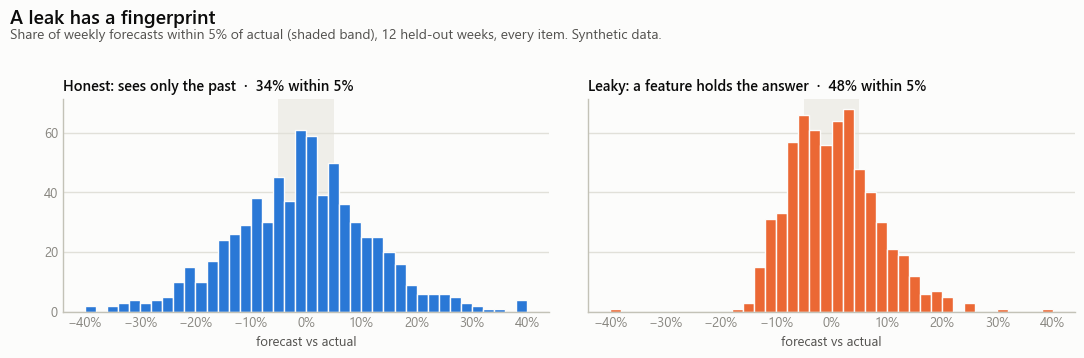

In [3]:
leak_fingerprint(honest, leaky, path=ROOT / "images" / "leak_fingerprint.png");

## 2. The decisive check: does the forecast move with its own answer?

Multiply the actual for one held-out week by ten and refit. An honest forecast for that week cannot change, because it never sees that week.

In [4]:
data = complete_weeks(weekly, synthetic.AS_OF)
origin = synthetic.AS_OF - pd.Timedelta(weeks=11)
week = synthetic.AS_OF - pd.Timedelta(weeks=5)
rows = []
for sku in ["A-01", "B-04", "C-07", "E-03"]:
    item = data[data["sku"] == sku]
    rows.append({"item": sku,
                 "honest_forecast_moves": leakage.moves_with_its_own_answer(item, week, origin, leak=False),
                 "leaky_forecast_moves": leakage.moves_with_its_own_answer(item, week, origin, leak=True)})
pd.DataFrame(rows).set_index("item").map("{:+.0%}".format)

,honest_forecast_moves,leaky_forecast_moves
item,,
A-01,+0%,+421%
B-04,+0%,+457%
C-07,+0%,+421%
E-03,+0%,+455%


## Key findings

- A leak does not announce itself: the code runs, the backtest improves, and every number looks better than the last model's.
- A pleasant surprise is the signal. A jump in value added over naive, and an unusual share of forecasts within 5% of actual, are both reasons to test further before shipping.
- The own-answer test is decisive: a forecast that moves when its own target changes is reading the future.
- Without the leaky feature there is nothing left to add. That is what "I built it, it looked good, I did not believe it, it was wrong, and I did not ship it" looks like in code.